$$\text{Blossom benchmarks}$$

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.axes import Axes

---
## Configuration
---

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "tests" / "benchmarks" / "results"

In [3]:
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"

BACKEND = {"scalar": BLUE, "avx512": ORANGE}
OPERATION = {"lookup": BLUE, "insert": ORANGE, "merge": AQUA}
PATTERN = {"blocked": BLUE, "scattered": ORANGE}

sns.set_theme(
    context="notebook",
    style="whitegrid",
    rc={
        "figure.figsize": (8, 4.5),
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "text.color": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "lines.linewidth": 2,
        "lines.markersize": 6,
        "legend.frameon": False,
    },
)

In [4]:
CACHES: list[tuple[int, str]] = [(48 << 10, "L1d"), (1 << 20, "L2"), (32 << 20, "L3")]

---
## Plot helper methods
---

In [5]:
def mark_caches(ax: Axes) -> None:
    """
    Vertical hairlines where the working set outgrows each cache level.
    """
    for size, label in CACHES:
        ax.axvline(size, color=MUTED, lw=1, ls=(0, (4, 3)), zorder=0)
        ax.annotate(
            label,
            (size, 1.0),
            xycoords=("data", "axes fraction"),
            xytext=(3, -11),
            textcoords="offset points",
            color=MUTED,
            fontsize=8,
        )


def label_ends(
    ax: Axes, frame: pd.DataFrame, x: str, y: str, hue: str, palette: dict[str, str]
) -> None:
    """
    Direct-label each series at its last point, so identity is never colour alone.
    """
    for name, group in frame.groupby(hue, observed=True):
        last = group.sort_values(x).iloc[-1]
        ax.annotate(
            f"  {name}",
            (last[x], last[y]),
            color=palette[name],
            fontsize=9,
            fontweight="bold",
            va="center",
        )
    # Room for the labels at the right edge, and headroom under the cache marks.
    ax.margins(x=0.18, y=0.10)


throughput = pd.read_csv(RESULTS / "throughput.csv")
locality = pd.read_csv(RESULTS / "locality.csv")
hitrate = pd.read_csv(RESULTS / "hitrate.csv")
fpr = pd.read_csv(RESULTS / "fpr.csv").sort_values("target_fpr")

---
## Plots
---

### Lookup throughput

,backend,operation,keys,filter_bytes,ops,seconds,million_ops_per_sec
1,scalar,lookup,25000,30272,4000000,0.037657966,106.220000000
4,avx512,lookup,25000,30272,4000000,0.004057531,985.820000000
7,scalar,lookup,100000,121024,4000000,0.040165957,99.590000000
10,avx512,lookup,100000,121024,4000000,0.004517105,885.520000000
13,scalar,lookup,500000,605120,4000000,0.041234261,97.010000000
16,avx512,lookup,500000,605120,4000000,0.004691414,852.620000000
19,scalar,lookup,1000000,1210240,4000000,0.043685582,91.560000000
22,avx512,lookup,1000000,1210240,4000000,0.005804995,689.060000000
25,scalar,lookup,5000000,6051008,4000000,0.045550610,87.810000000
28,avx512,lookup,5000000,6051008,4000000,0.006765151,591.270000000


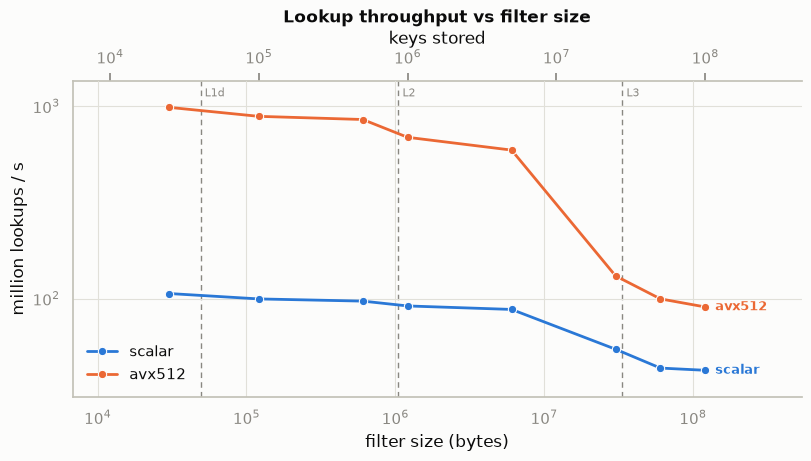

In [6]:
lookup = throughput[throughput.operation == "lookup"]
display(lookup.style.format(precision=9))

fig, ax = plt.subplots(layout="constrained")
sns.lineplot(
    data=lookup,
    x="filter_bytes",
    y="million_ops_per_sec",
    hue="backend",
    palette=BACKEND,
    marker="o",
    errorbar=None,
    ax=ax,
)

mark_caches(ax)
label_ends(ax, lookup, "filter_bytes", "million_ops_per_sec", "backend", BACKEND)
ax.set(
    xscale="log",
    yscale="log",
    xlabel="filter size (bytes)",
    ylabel="million lookups / s",
    title="Lookup throughput vs filter size",
)
ax.legend(title=None, loc="lower left")
sns.despine()

bits_per_key = (lookup.filter_bytes * 8 / lookup["keys"]).median()
keys_axis = ax.secondary_xaxis(
    "top",
    functions=(
        lambda size: size * 8 / bits_per_key,
        lambda keys: keys * bits_per_key / 8,
    ),
)
keys_axis.set_xlabel("keys stored")
keys_axis.tick_params(which="minor", length=0)

### Vectorization speedup

backend,operation,filter_bytes,avx512,scalar,speedup
0,insert,30272,1214.300000000,336.850000000,3.604868636
1,insert,121024,1085.020000000,320.540000000,3.384975354
2,insert,605120,760.370000000,310.800000000,2.446492921
3,insert,1210240,755.460000000,279.140000000,2.706383893
4,insert,6051008,652.050000000,245.430000000,2.656765677
5,insert,30254784,154.260000000,63.000000000,2.448571429
6,insert,60509568,107.150000000,39.060000000,2.743215566
7,insert,121019136,98.570000000,35.420000000,2.782891022
8,lookup,30272,985.820000000,106.220000000,9.280926379
9,lookup,121024,885.520000000,99.590000000,8.891655789


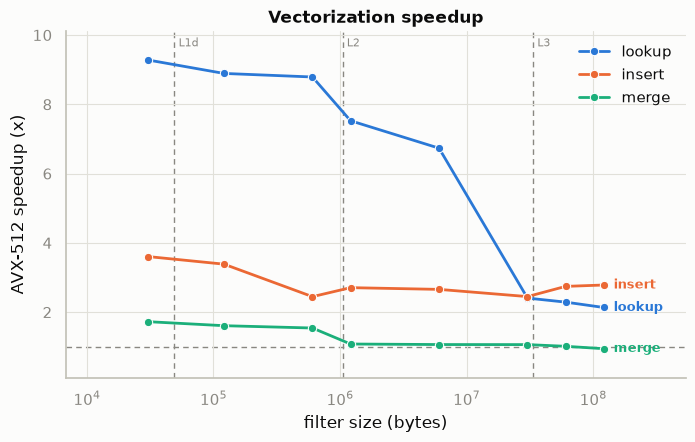

In [7]:
speedup = throughput.pivot_table(
    index=["operation", "filter_bytes"], columns="backend", values="million_ops_per_sec"
).reset_index()

if "avx512" not in speedup:
    raise SystemExit("scalar-only results, rebuild with -DBLOSSOM_AVX512=ON")

speedup["speedup"] = speedup["avx512"] / speedup["scalar"]
display(speedup.style.format(precision=9))

fig, ax = plt.subplots()
sns.lineplot(
    data=speedup,
    x="filter_bytes",
    y="speedup",
    hue="operation",
    palette=OPERATION,
    hue_order=list(OPERATION),
    marker="o",
    errorbar=None,
    ax=ax,
)

ax.axhline(1.0, color=MUTED, lw=1, ls=(0, (4, 3)), zorder=0)
mark_caches(ax)
label_ends(ax, speedup, "filter_bytes", "speedup", "operation", OPERATION)
ax.set(
    xscale="log",
    xlabel="filter size (bytes)",
    ylabel="AVX-512 speedup (x)",
    title="Vectorization speedup",
)
ax.legend(title=None)
sns.despine()

### Locality

,pattern,array_bytes,keys,seconds,ns_per_key,memory_ns
0,blocked,32768,5000000,0.006709421,1.342000000,0.000000000
1,scattered,32768,5000000,0.017950572,3.590000000,0.000000000
2,blocked,131072,5000000,0.007698582,1.540000000,0.198000000
3,scattered,131072,5000000,0.018958526,3.792000000,0.202000000
4,blocked,524288,5000000,0.007861511,1.572000000,0.230000000
5,scattered,524288,5000000,0.019342140,3.868000000,0.278000000
6,blocked,2097152,5000000,0.010825712,2.165000000,0.823000000
7,scattered,2097152,5000000,0.026848046,5.370000000,1.780000000
8,blocked,8388608,5000000,0.011381541,2.276000000,0.934000000
9,scattered,8388608,5000000,0.027634282,5.527000000,1.937000000


scattered costs 3.17x the memory time of blocked at the largest size


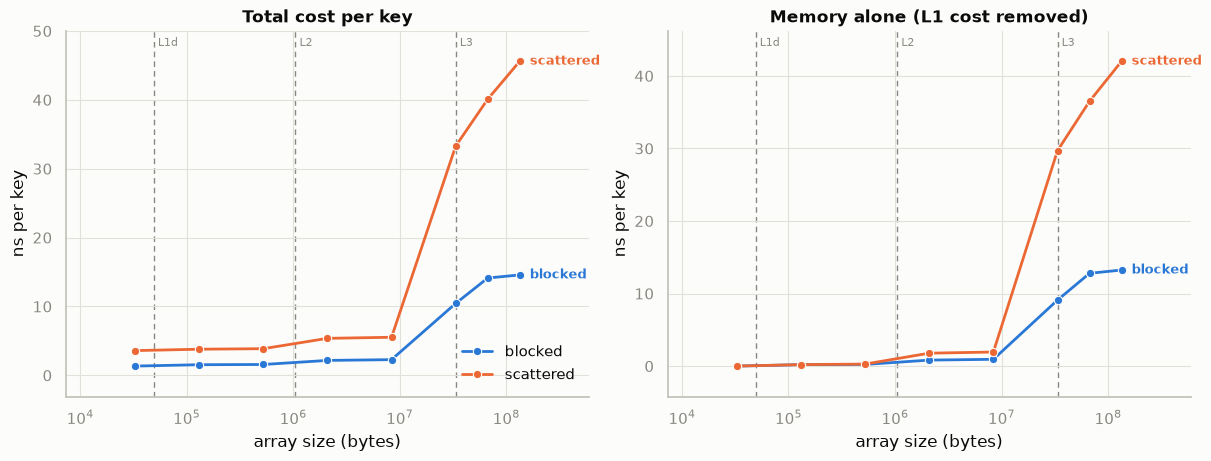

In [8]:
smallest = locality.array_bytes.min()
baseline = locality[locality.array_bytes == smallest].set_index("pattern").ns_per_key
locality["memory_ns"] = locality.ns_per_key - locality.pattern.map(baseline)
display(locality.style.format(precision=9))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")

for ax, column, title in zip(
    axes,
    ["ns_per_key", "memory_ns"],
    ["Total cost per key", "Memory alone (L1 cost removed)"],
):
    sns.lineplot(
        data=locality,
        x="array_bytes",
        y=column,
        hue="pattern",
        palette=PATTERN,
        hue_order=list(PATTERN),
        marker="o",
        errorbar=None,
        ax=ax,
        legend=ax is axes[0],
    )
    mark_caches(ax)
    label_ends(ax, locality, "array_bytes", column, "pattern", PATTERN)
    ax.set(xscale="log", xlabel="array size (bytes)", ylabel="ns per key", title=title)

axes[0].legend(title=None, loc="lower right")
sns.despine()

ratio = locality.pivot_table(index="array_bytes", columns="pattern", values="memory_ns")
print(
    f"scattered costs {ratio.scattered.iloc[-1] / ratio.blocked.iloc[-1]:.2f}x "
    f"the memory time of blocked at the largest size"
)

### Measured vs estimated FPR

,target_fpr,keys,probes,filter_bits,bits_per_key,measured_fpr,estimated_fpr,overshoot
3,0.000100000,100000000,100000000,2104541184,21.045000000,0.000194420,0.000194060,1.944200000
2,0.001000000,100000000,100000000,1460769792,14.608000000,0.001487570,0.001494640,1.487570000
1,0.010000000,100000000,100000000,968153088,9.682000000,0.012244540,0.012254720,1.224454000
0,0.100000000,100000000,100000000,577254400,5.773000000,0.106685260,0.106722770,1.066852600


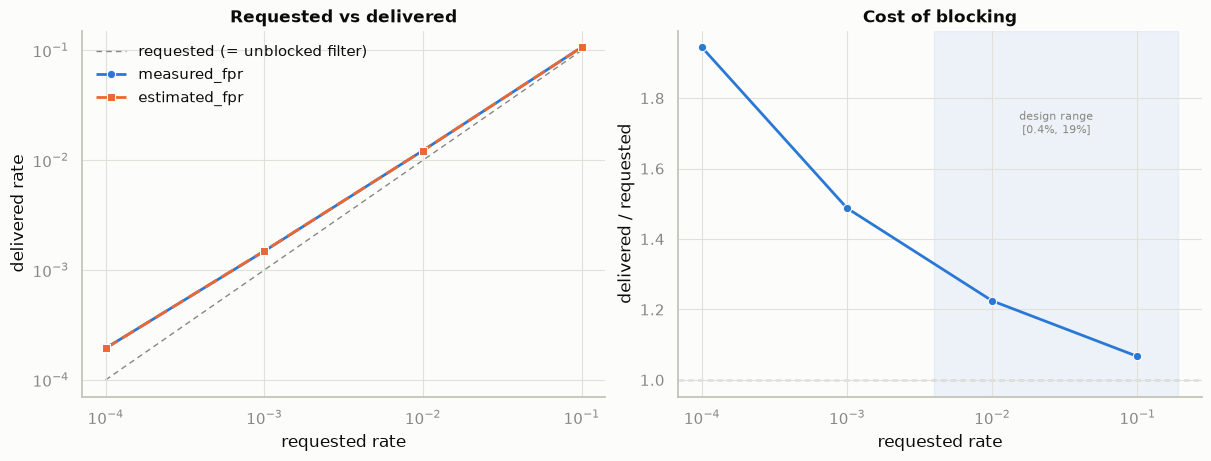

In [9]:
display(
    fpr.assign(overshoot=fpr.measured_fpr / fpr.target_fpr).style.format(precision=9)
)

tidy = fpr.melt(
    id_vars="target_fpr",
    value_vars=["measured_fpr", "estimated_fpr"],
    var_name="series",
    value_name="rate",
)
SERIES = {"measured_fpr": BLUE, "estimated_fpr": ORANGE}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")

axes[0].plot(
    fpr.target_fpr,
    fpr.target_fpr,
    color=MUTED,
    lw=1,
    ls=(0, (4, 3)),
    label="requested (= unblocked filter)",
    zorder=0,
)

sns.lineplot(
    data=tidy,
    x="target_fpr",
    y="rate",
    hue="series",
    palette=SERIES,
    hue_order=list(SERIES),
    style="series",
    style_order=list(SERIES),
    markers=["o", "s"],
    dashes=[(1, 0), (5, 2)],
    errorbar=None,
    ax=axes[0],
)
axes[0].set(
    xscale="log",
    yscale="log",
    xlabel="requested rate",
    ylabel="delivered rate",
    title="Requested vs delivered",
)
axes[0].legend(title=None, loc="upper left")

# The design's useful range (according to Apple's split-block paper).
axes[1].axvspan(0.004, 0.19, color=BLUE, alpha=0.07, zorder=0)
axes[1].axhline(1.0, color=MUTED, lw=1, ls=(0, (4, 3)), zorder=0)
sns.lineplot(
    x=fpr.target_fpr,
    y=fpr.measured_fpr / fpr.target_fpr,
    color=BLUE,
    marker="o",
    errorbar=None,
    ax=axes[1],
)
axes[1].annotate(
    "design range\n[0.4%, 19%]",
    (0.0276, 0.72),
    xycoords=("data", "axes fraction"),
    color=MUTED,
    fontsize=8,
    ha="center",
)
axes[1].set(
    xscale="log",
    xlabel="requested rate",
    ylabel="delivered / requested",
    title="Cost of blocking",
)

sns.despine()

### Hit rate

,backend,hit_rate,keys,filter_bytes,probes,seconds,million_lookups_per_sec
0,scalar,0.000000000,500000,605120,5000000,0.052535542,95.170000000
1,scalar,0.100000000,500000,605120,5000000,0.054076798,92.460000000
2,scalar,0.200000000,500000,605120,5000000,0.050777133,98.470000000
3,scalar,0.300000000,500000,605120,5000000,0.047687651,104.850000000
4,scalar,0.400000000,500000,605120,5000000,0.044722537,111.800000000
5,scalar,0.500000000,500000,605120,5000000,0.042492039,117.670000000
6,scalar,0.600000000,500000,605120,5000000,0.038873213,128.620000000
7,scalar,0.700000000,500000,605120,5000000,0.034562095,144.670000000
8,scalar,0.800000000,500000,605120,5000000,0.030568151,163.570000000
9,scalar,0.900000000,500000,605120,5000000,0.027109839,184.430000000


backend,avx512,scalar,speedup
hit_rate,,,
0.000000,795.600000000,95.170000000,8.359777241
0.100000,782.820000000,92.460000000,8.466580143
0.200000,777.530000000,98.470000000,7.896110491
0.300000,793.200000000,104.850000000,7.565092990
0.400000,783.500000000,111.800000000,7.008050089
0.500000,787.890000000,117.670000000,6.695759327
0.600000,813.550000000,128.620000000,6.325221583
0.700000,814.570000000,144.670000000,5.630538467
0.800000,801.280000000,163.570000000,4.898697805


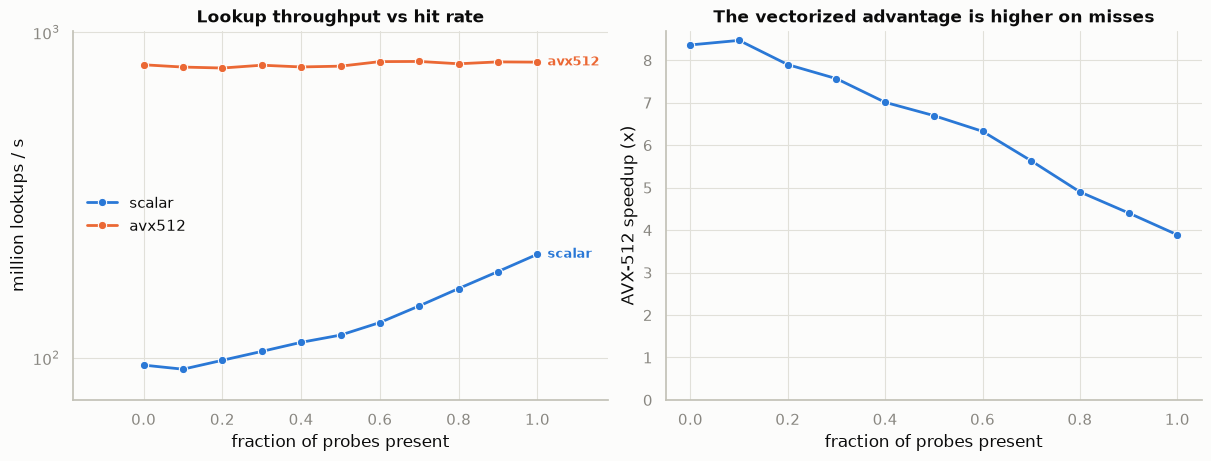

In [10]:
display(hitrate.style.format(precision=9))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")

sns.lineplot(
    data=hitrate,
    x="hit_rate",
    y="million_lookups_per_sec",
    hue="backend",
    palette=BACKEND,
    marker="o",
    errorbar=None,
    ax=axes[0],
)
label_ends(axes[0], hitrate, "hit_rate", "million_lookups_per_sec", "backend", BACKEND)
axes[0].set(
    yscale="log",
    xlabel="fraction of probes present",
    ylabel="million lookups / s",
    title="Lookup throughput vs hit rate",
)
axes[0].legend(title=None, loc="center left")

by_rate = hitrate.pivot_table(
    index="hit_rate", columns="backend", values="million_lookups_per_sec"
)
display(
    by_rate.assign(speedup=by_rate["avx512"] / by_rate["scalar"]).style.format(
        precision=9
    )
)
if "avx512" in by_rate:
    sns.lineplot(
        x=by_rate.index,
        y=by_rate["avx512"] / by_rate["scalar"],
        color=BLUE,
        marker="o",
        errorbar=None,
        ax=axes[1],
    )
    axes[1].set(
        xlabel="fraction of probes present",
        ylabel="AVX-512 speedup (x)",
        ylim=(0, None),
        title="The vectorized advantage is higher on misses",
    )

sns.despine()